## <center> Medical Insurance Cost Prediction </center>
##### <center> Hassan Ayoub </center>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
data = pd.read_csv('../data/insurance.csv')

print(f'Dataset Shape: {data.shape}')

print("\nColumns:", data.columns.tolist())
print("\nFirst 5 rows:")
print(data.head())

# Regions have been classified using numbers, same for Sex

Dataset Shape: (1338, 7)

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

First 5 rows:
   age  sex     bmi  children  smoker  region      charges
0   19    0  27.900         0       1       3  16884.92400
1   18    1  33.770         1       0       2   1725.55230
2   28    1  33.000         3       0       2   4449.46200
3   33    1  22.705         0       0       1  21984.47061
4   32    1  28.880         0       0       1   3866.85520


In [3]:
# Summary statistics
print("\nSummary Statistics:")
print(data.describe())

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())


Summary Statistics:
               age          sex          bmi     children       smoker  \
count  1338.000000  1338.000000  1338.000000  1338.000000  1338.000000   
mean     39.207025     0.505232    30.663397     1.094918     0.204783   
std      14.049960     0.500160     6.098187     1.205493     0.403694   
min      18.000000     0.000000    15.960000     0.000000     0.000000   
25%      27.000000     0.000000    26.296250     0.000000     0.000000   
50%      39.000000     1.000000    30.400000     1.000000     0.000000   
75%      51.000000     1.000000    34.693750     2.000000     0.000000   
max      64.000000     1.000000    53.130000     5.000000     1.000000   

            region       charges  
count  1338.000000   1338.000000  
mean      1.515695  13270.422265  
std       1.104885  12110.011237  
min       0.000000   1121.873900  
25%       1.000000   4740.287150  
50%       2.000000   9382.033000  
75%       2.000000  16639.912515  
max       3.000000  63770.428010

### Exploratory Data Analysis
Before modeling, let's look at how charges are distributed and how they relate to the key drivers in the data.

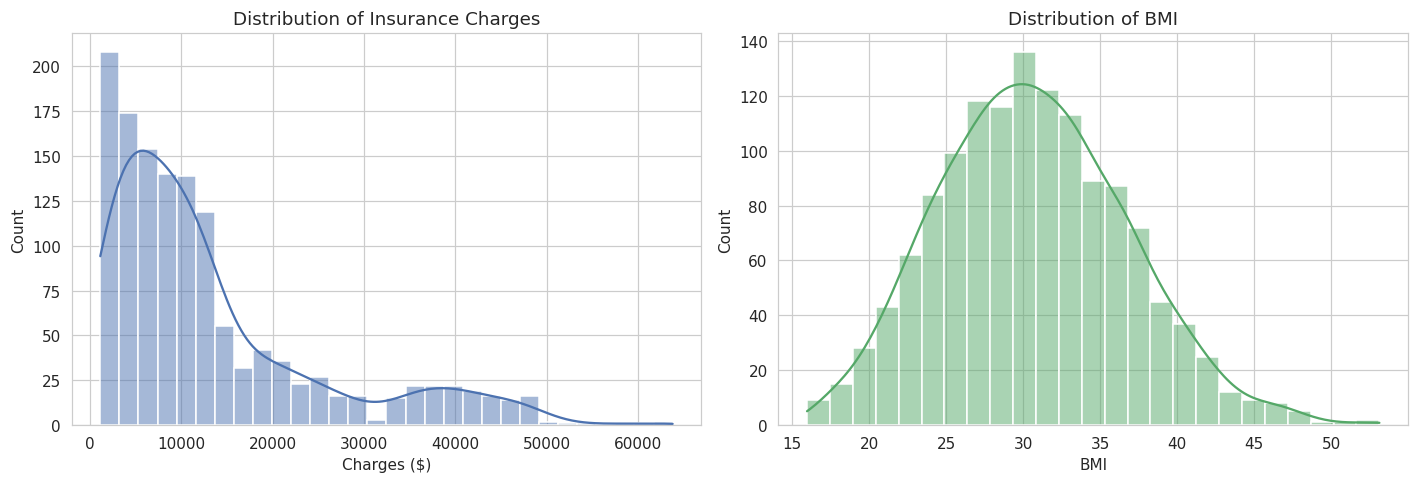

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data['charges'], bins=30, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Distribution of Insurance Charges")
axes[0].set_xlabel("Charges ($)")

sns.histplot(data['bmi'], bins=25, kde=True, color="#55A868", ax=axes[1])
axes[1].set_title("Distribution of BMI")
axes[1].set_xlabel("BMI")

plt.tight_layout()
plt.show()

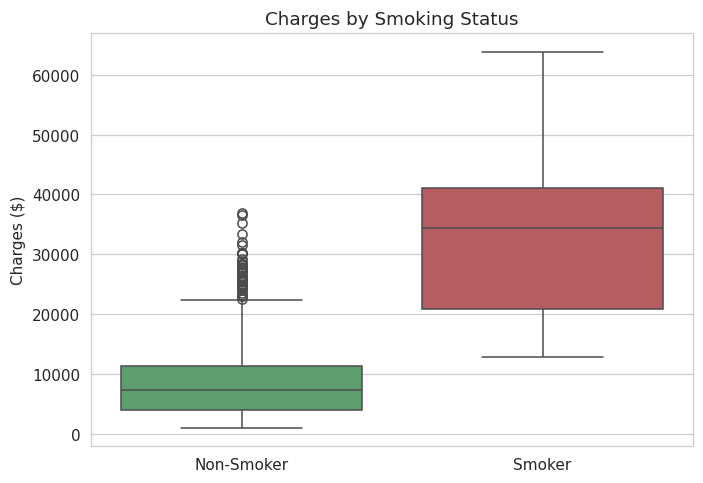

Average charges - Smokers:    $32050.23
Average charges - Non-smokers: $8434.27


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.boxplot(data=data, x='smoker', y='charges', hue='smoker', palette=["#55A868", "#C44E52"], legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-Smoker', 'Smoker'])
ax.set_title("Charges by Smoking Status")
ax.set_xlabel("")
ax.set_ylabel("Charges ($)")
plt.tight_layout()
plt.show()

print("Average charges - Smokers:    $%.2f" % data.loc[data['smoker'] == 1, 'charges'].mean())
print("Average charges - Non-smokers: $%.2f" % data.loc[data['smoker'] == 0, 'charges'].mean())

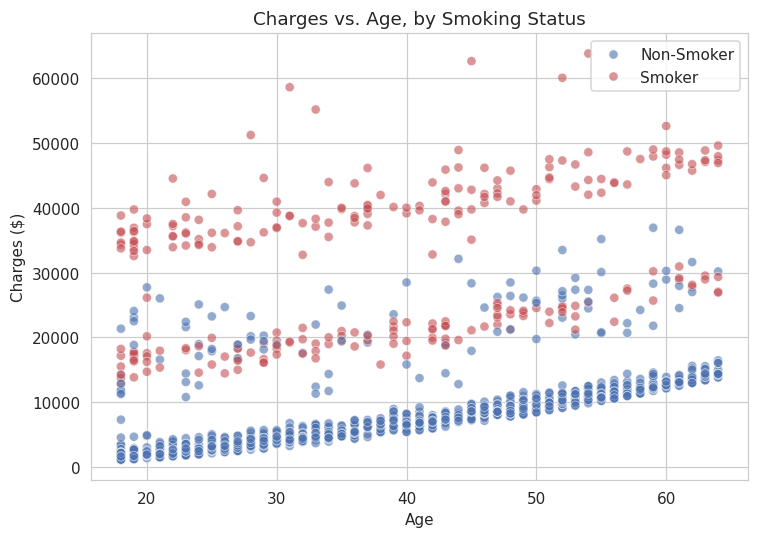

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
scatter = sns.scatterplot(
    data=data, x='age', y='charges', hue='smoker',
    palette={0: "#4C72B0", 1: "#C44E52"}, alpha=0.6, ax=ax
)
ax.set_title("Charges vs. Age, by Smoking Status")
ax.set_xlabel("Age")
ax.set_ylabel("Charges ($)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-Smoker', 'Smoker'], title="")
plt.tight_layout()
plt.show()

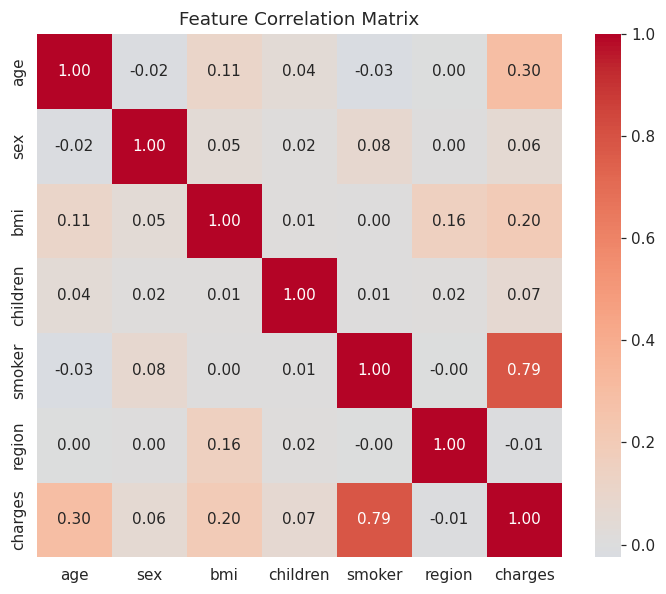

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = data.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Smoking status and age stand out as the strongest drivers of insurance charges, with BMI adding a secondary effect, consistent with what the correlation matrix and scatter plot above show.

In [8]:
X = data[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = data['charges']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1338, 6)
Target shape: (1338,)


In [9]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X = poly.fit_transform(X)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1070
Testing samples: 268


In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
y_pred = model.predict(X_test_scaled)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MAE: 2730.3155816804374
R²: 0.867756671853774


### Model Evaluation

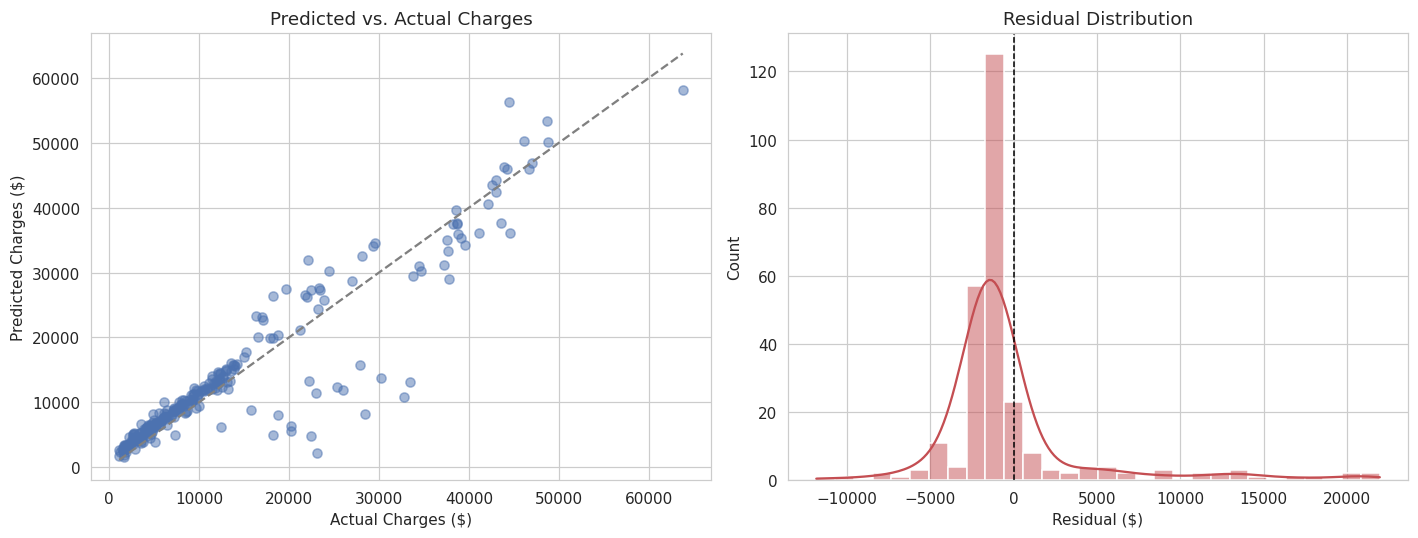

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5, color="#4C72B0")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, '--', color="gray", linewidth=1.5)
axes[0].set_xlabel("Actual Charges ($)")
axes[0].set_ylabel("Predicted Charges ($)")
axes[0].set_title("Predicted vs. Actual Charges")

residuals = y_test - y_pred
sns.histplot(residuals, bins=30, kde=True, color="#C44E52", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual ($)")

plt.tight_layout()
plt.show()